# Day 07-Quantum Error Correction Techniques: Generalized Repetition Code(Five Qubit)
The quantum repetition code is the fundamental quantum error correction techniques thar protect logical quantum information by distributing it across by the multiple physical qubits.

In this notebook we will focus on,five qubit generalized repetition code.unlike previously implemented three qubit bit flip code ,our focus is extending the repetition principle for larger odd number of physical qubits.

#### why it is important ?
the repition code introduces a scalable approch to protecting quantum information against bit flip errors.it demonstrate how increasing the number of physical qubit can increase the number of bit flip errors that code can be correct.

**In this notebook we will learn** :

- Generalized quantum repetition encoding
- Relationship with the three-qubit bit flip code.
- Five qubit repetition code construction.
- Stabilizers generators and parity checks
- Syndrome controlled error recovery
- Measurement and Logical state comparision.

#### Mathematical Background :
We will study the generalised  logical encoding eqaution and stabilizers generators,error syndrome and error correction capability of an odd length repetition code .

#### Qiskit Implementation :
We will implemented the five qubit repetition code using Qiskit and Aer simulator .the implentation will used the five physical data and four ancilla  qubit for syndrome extraction and controlled operation for error correction.

#### Expectect Result :
We will compare the measurement distribution before and after error correction to demonstrate how repitition code restore the encoded logical information.

## Introduction to Quantum Repetition Code
The generalised repitition code extend the repetition principle to an arbitary odd number of physical qubit. Istead of restricting the encoding to three physical qubits ,we can enode one logical qubit using :

$ n=2t+1 $

where:
- $n$ : represent the number of physical data qubit.
- $t$ : represent the maximum number of bit flip error that can be corrected.

for an odd length repetition code ,the logical basis state are :

$|0_L\rangle=|0\rangle ^ {\otimes n}$

$|1_L\rangle=|1\rangle ^ {\otimes n}$

An arbitary Quantum logical state:

$ \psi\rangle=\alpha |0\rangle+\beta|1\rangle$

is encoded as :

after encoding state becomes:
$ \psi_L\rangle=\alpha |000\rangle^{\otimes n}+\beta|111\rangle^{\otimes n}$

#### Five Qubit Example :
for this notebook , we choose  $(n=5)$. so the logical encoded state become :

$0_L\rangle=|00000\rangle$

$1_L\rangle=|11111\rangle$

therefore,

$ psi_L\rangle=\alpha |00000\rangle+\beta|11111\rangle$

This encoding provides protection against up to two bit flip errors. our implementation will demonstrate the correction of one deliberatly introduced the errors.

#### Mathematical Background
The generalized repetition code uses neighbouring qubit parity checks to detect bilt flip errors. for an n-qubits repetition codes ,the stabilizer generators are :

$ S_i=Z_iZ_{i+1} $

where :
- $i=0,1,\ldots,n-2$

for the five qubit repetition code ,stabilizers are :
- S_0=Z_0Z_1 $
- S_1=Z_1Z_2 $
- S_2=Z_2Z_3 $
- S_3=Z_3Z_4 $

this four stabilizers are checks the parity between neighbouring physical qubits .

#### Error-Correction Capability

for an odd-length repetition code : $ t=\frac{n-1}{2} $

for five physical qubit : $ t=\frac{5-1}{2} =2 $

Therefore , the code can correct up to two bit-flip errors.

### Syndrome implementation :
A bit-flip error changes the eigenvalue of the stabilizers involving the affected qubit.for the five qubit code :

|Error | Syndrome (S0 S1 S2 S3) |
|----|----|
|No Error |0000|
|X on q0 |1000|
|X on q1 |1100|
|X on q2 |0110|
|X on q3 |0011|
|X on q4 |0001|

Syndrome identifies the location of a single bit flip error ,but its protection is therefore limited to a perticular error type.

#### Main difference between Bit-flip Code and Repitition Code 

The Bit flip Code and Quantum Repetition code are closely  mathematically related concepts in Quantum Error Correction.

The three qubit bit flip code is actually a specific implementation of  quantum repetition code ,bothe used the redundent encoding to protect the quantum information against bit flip errors.

The main difference is that ** generalized repetition codes allows the encoding to be extended to larger odd number physical qubits  where as the three qubit bit flip code is its quantum information against the bit flip errors for small odd length which capable to correcting single bit flip error.**

- **Bit flip Code** :
The three qubit bit flip code protects quantum information against the single Puali-X error.its encode the one logical qubit as:

$|0_L\rangle=|000\rangle$ and $|1_L\rangle=|111\rangle$

an arbitary logical state becomes:
$|\psi_L\rangle=\alpha|000\rangle + \beta|111\rangle$

it uses the parity check to identify the which physical qubit experienced the bit flip error.

- **Repetition Code** :
A repetition code uses  the redundent representation information  so that error can be detected and corrected using parity information. in classical computing bit can be encoded as:

$ 0\rightarrow 00000 $ and  $ 1\rightarrow 11111 $ 

the majority value is used to recover the original information.in quantum computiong the repition principle is extended as quantum superposition state :

$\alpha|0\rangle + \beta|1\rangle\rightarrow \alpha|00000\rangle + \beta|11111\rangle$

This allow the code to preserve the qunatum amplitude while detecting bit flip error through stabilizer measurement.

#### Bit-flip code Vs Repetition Code

| Feature | 3-Qubit Bit-Flip Code | Generalized Repetition Code |
|---- |----|----|
|Physical Qubit | 3 |Arbitary odd number |
|Encoding |3-Qubit Repetition | Generalized Repitition |
| Error Correction | One X error | Up to (n-1)/2 X error |
| Syndrome Checks | 2 | n-1 |
| Scalability |Fixed 3-Qubit example |Extendable to larger odd n |
| Implementation here | 3-Qubit Construction | 5 -Qubit Construction |

**Important** : These are not fundamentally independent codes. the three qubit bit-flip code is a special case of the generalized quantum repetition code. this implementation provide a border understanding of repetition based quantum error correction rather than repeating the prvious 3-qubit implementation.



## Import Required Libraries

In [1]:
from qiskit import QuantumCircuit,transpile
from qiskit.circuit.library import MCXGate
from qiskit_aer import AerSimulator
import numpy as np
import matplotlib.pyplot as plt

## Step 1 -Prepare the Logical Quantum State 
we begin by preparing a logical superposition state : $ |\psi\rangle=|+\rangle $

where :
$ |+\rangle=\frac{|0\rangle+|1\rangle}{\sqrt{2}} $

A Hadamard gate creates this superposition .
next ,four CNOT gates distributing the logical information from the first physical qubit to the remaining four physical qubits.the resulting encoded state is :

$ |\psi_L\rangle=\frac{00000\rangle + |11111\rangle}{\sqrt{2}} $ 

this is the five-qubit logical repetition state.

##### Qubit Arrangement 

We use nine total qubits :
- q0-q4: Five Physical data qubits 
- q5-q8 : Four ancilla qubits for syndrome extraction.

The four ancillas corrospond to the four stabilizers checks.

In [2]:
# define five physical data qubits 
N=5

# four syndrome ancilla qubits
ANCILLA_COUNT=N-1

# total number of qubits
TOTAL_QUBITS=N+ANCILLA_COUNT

def encode_repetition(qc):
    """Encode one logical qubit into five physical qubits ."""

    #Prepare logical |+> state
    qc.h(0)
    # distribute logical information
    for i in range(1,N):
        qc.cx(0,i)

def extract_syndrome(qc):
    """Extract neighbouring parity checks"""
    for i in range(N-1):
        qc.cx(i,N+i)
        qc.cx(i+1,N+i)

def controlled_recovery(qc,syndrome,target):
    """Apply x correction for specified syndrome"""
    controls =list(range(N,TOTAL_QUBITS))

    # convert zero-control into one-control
    for qubit,bit in zip(controls,syndrome):
        if bit==0:
            qc.x(qubit)

    # Apply Multi-controlled X 
    qc.append(MCXGate(ANCILLA_COUNT),controls+[target])

    # Restore syndrome controls
    for qubit,bit in zip(controls,syndrome):
        if bit==0:
            qc.x(qubit)

def apply_repetition_recovery(qc):
    """correct any single bit-flip errors"""
    single_error_syndrome=[
        (1,0,0,0), #q0
        (1,1,0,0), #q1
        (0,1,1,0), #q2
        (0,0,1,1), #q3
        (0,0,0,1), #q4
    ]

    for target,syndrome in enumerate(single_error_syndrome):
        controlled_recovery(qc,syndrome,target)

## Step 2 - Introduce a Physical Qubit Error

After encoding the logical state ,we deliberatly introduce an x error on middle physical qubit ,q2. the error operation is :
$ X_2 $ 

before the error encoded state is :
$ |\psi_L\rangle=\frac{|00000\rangle + |11111\rangle}{\sqrt{2}}$

After the error :
$ |\psi'\rangle=\frac{|00100\rangle}{\sqrt{2}} $ 

The error changes the third physical qubit in both component of the logical superposition. we will first simulate the circuit without recovery to establish a baseline for comparision.

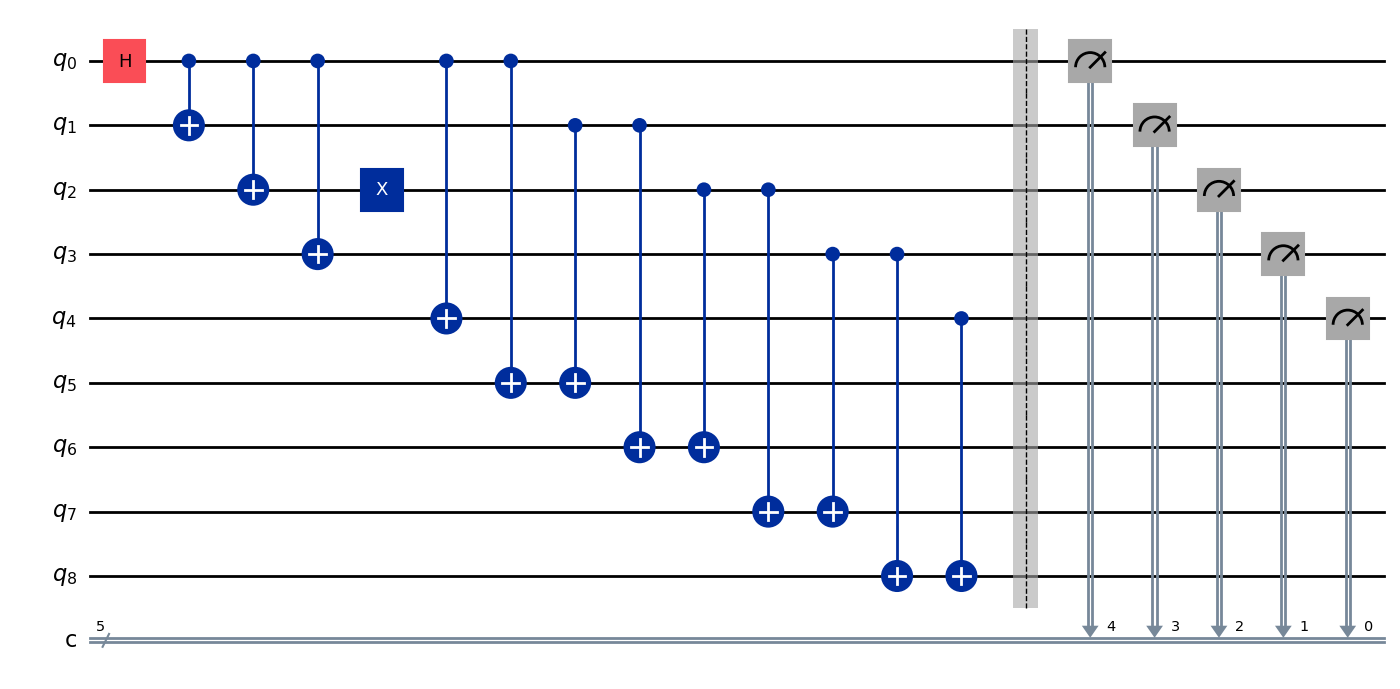

In [3]:
def build_repetition_circuit(error_qubit=None,correction=False):
    """ Build a generalized five qubit repetition circuit.
    
    error_qubit: Physical qubit receiving an X-error
    
    correction : whether syndrome-controlled receovery is applied"""

    qc=QuantumCircuit(TOTAL_QUBITS,N)

    #Step 1 : Logical Encoding 
    encode_repetition(qc)

    #Step 2 : Encode Physical Error
    if error_qubit is not None:
        qc.x(error_qubit)

    #Step 3: Extract Error Syndrome
    extract_syndrome(qc)

    #Step 4 : Apply Recovery 
    if correction:
        apply_repetition_recovery(qc)

    #Step 5 : Measure data qubits
    qc.barrier()

    # Reverse classical-bit mapping to displayed
    # Mesurement string follow q0,q1,q2,q3,q4

    for i in range(N):
        qc.measure(i,N-1-i)
    return qc

# circuit before error correction
uncorrected_circuit=build_repetition_circuit(error_qubit=2,correction=False)

# Display Circuit
uncorrected_circuit.draw("mpl")

## Step 3 - Extract the Error Syndrome
Syndrome extraction is performed using the ancilla qubits .each ancilla stores tha parity between two neighbouring physical qubits.the parity checks are :
- $S_0=Z_0Z_1$
- $S_1=Z_1Z_2$
- $S_2=Z_2Z_3$
- $S_3=Z_3Z_4$

for the introduce error on q2 :
- $S_0=+1$
- $S_1=-1$
- $S_2=-1$
- $S_3=+1$

therefore syndrome is : $\boxed{0110} $

this syndrome identifies the middle physical qubit as the location of the error.

##### why used ancilla qubits?
the ancillas allow us to extract parity information without directly measuring the logical data  qubits.in this implementation ,sydrome extraction and recovery are performed correctly.the syndrome ancillas are not measured seperatly.

## Step 4 : Apply Syndrome-controlled recovery 
after the extracting the syndrome ,the recovery circuit identifies the affected physical qubit . for our example:
$\text{syndrome}=0110$

the corrosponding correction is : $X_2$

Applying the correction gives : $X_2|\psi'\rangle=|\psi_L\rangle$

the original encoded state restored : $|\psi_L\rangle=\frac{|00000\rangle+|11111\rangle}{\sqrt{2}}$

### Recovery stratergy 
this implementation compare the extracted syndrome against the five possible single-qubit error syndromes. A multi-controlled X gate appplies the correction only when the ancilla pattern matches the corrosponding error. this is a coherent implementation of syndrom-based recovery.

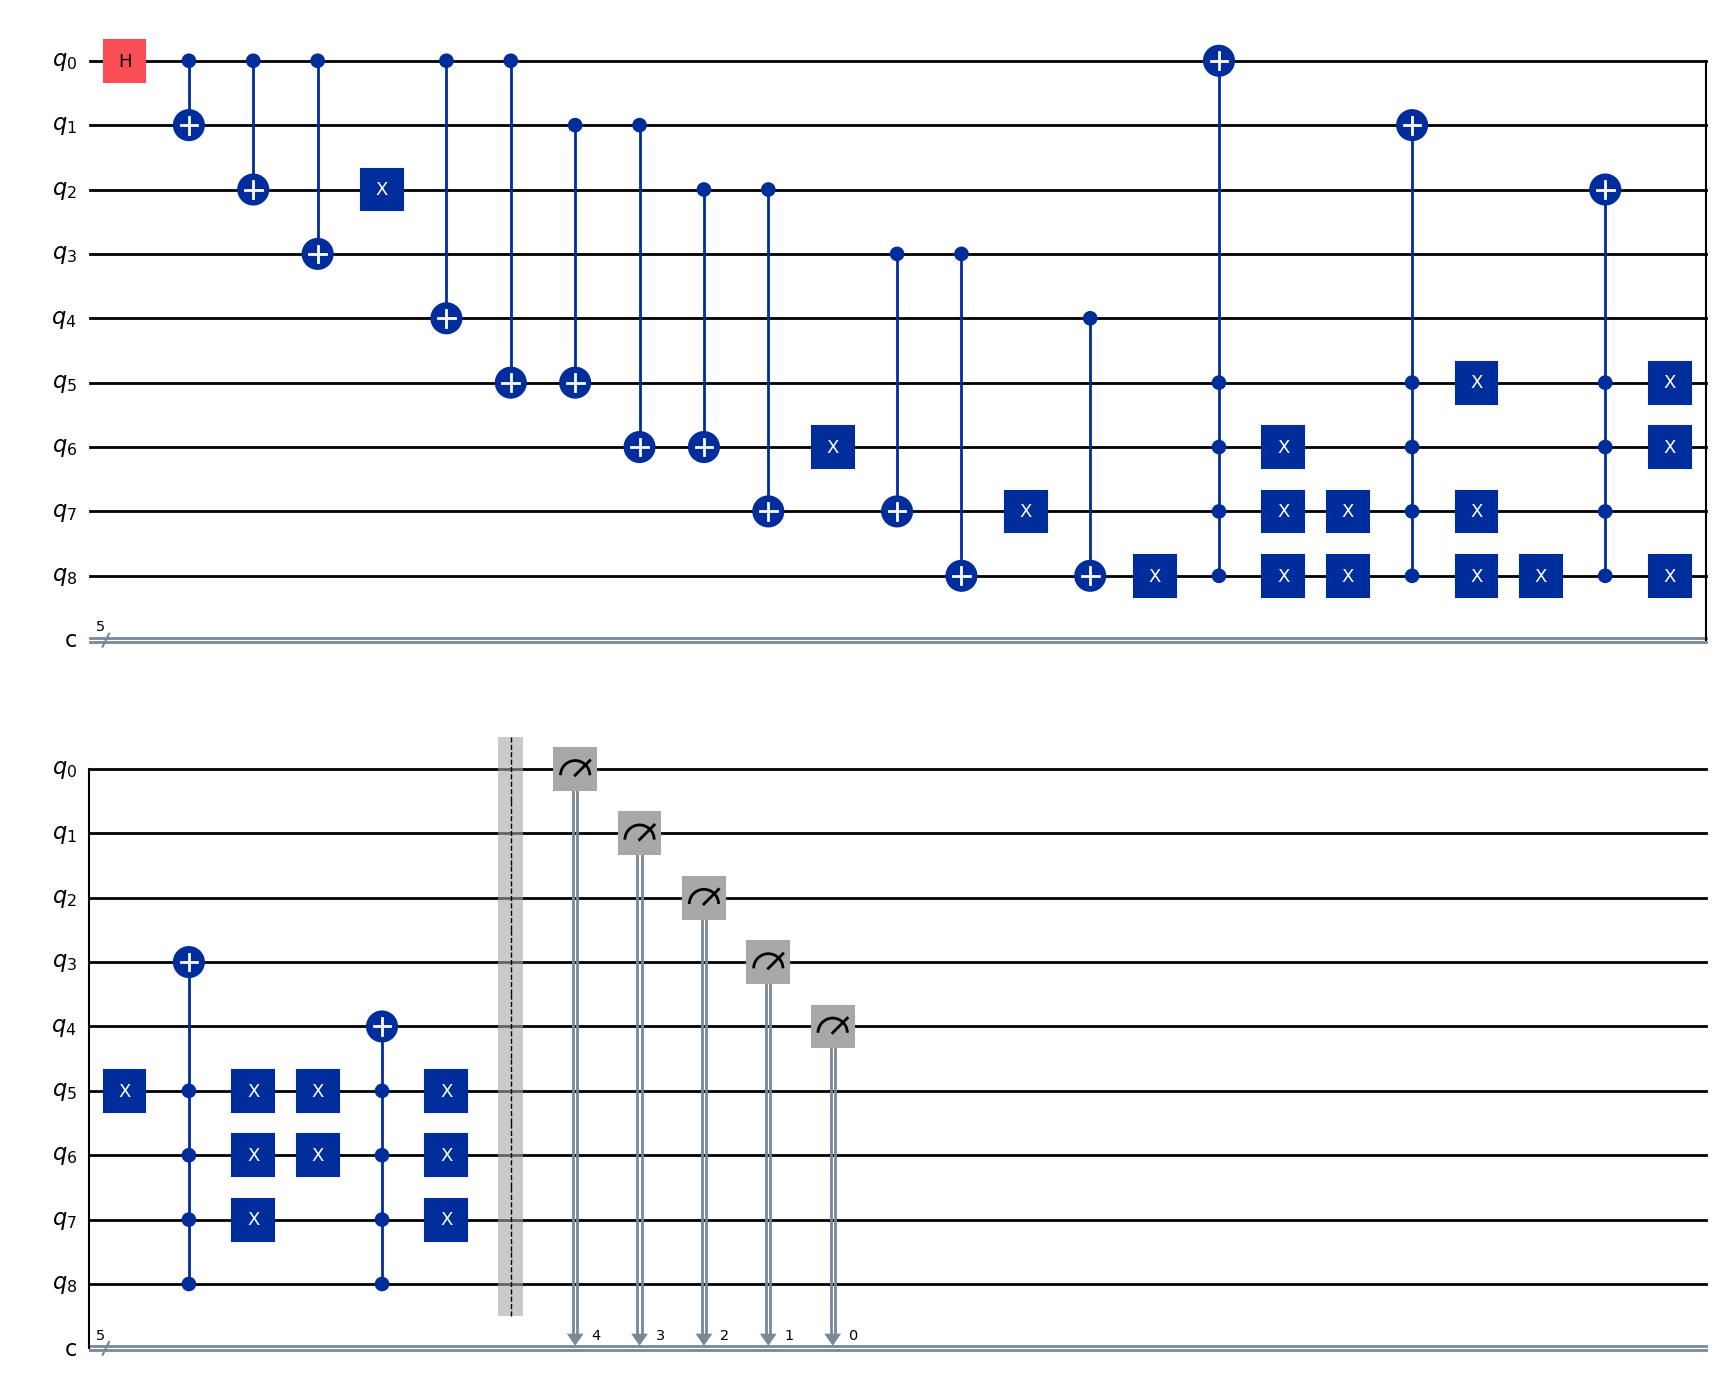

In [4]:
corrected_circuit=build_repetition_circuit(error_qubit=2,correction=True)

corrected_circuit.draw("mpl")

## Run On Simulator

In [5]:
simulator=AerSimulator()
shots=4096
compiled_before=transpile(uncorrected_circuit,simulator)
compiled_after=transpile(corrected_circuit,simulator)
result_before=simulator.run(compiled_before,shots=shots,seed_simulator=42).result()
result_after=simulator.run(compiled_after,shots=shots,seed_simulator=42).result()
count_before=result_before.get_counts()
count_after=result_after.get_counts()
print("Before Error Correction")
print(count_before)
print("\n after Error correction")
print(count_after)

Before Error Correction
{'11011': 1972, '00100': 2124}

 after Error correction
{'11111': 2074, '00000': 2022}


## Result Visualization

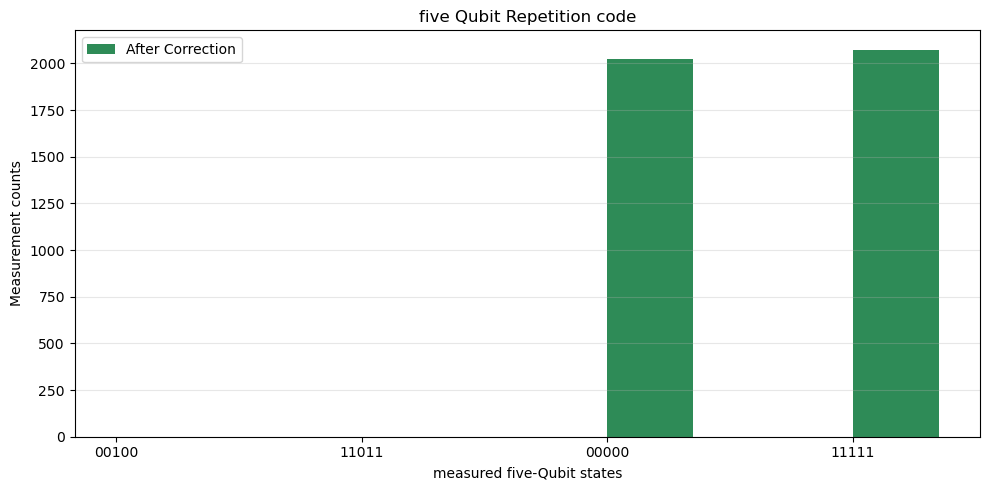

In [7]:
states=[
    "00100",
    "11011",
    "00000",
    "11111"
]
before_values=[count_before.get(state,0) for state in states]
after_values=[count_after.get(state,0) for state in states]

x=np.arange(len(states))
width=0.35

plt.figure(figsize=(10,5))

plt.bar(x+width/2,after_values,width,label="After Correction",color="seagreen")
plt.xlabel("measured five-Qubit states")
plt.ylabel("Measurement counts")
plt.title("five Qubit Repetition code")
plt.xticks(x,states)
plt.legend()
plt.grid(axis="y",alpha=0.3)
plt.tight_layout()
plt.show()

#### Result Analysis
The graph compares the measurement distribution before and after error correction:
- **X-axis** : The X-axis represents the measured five-qubit computational basis states.
- **y-axis** : The y-xis represents the number of measurement outcomes observed across 4096 simulation shots.
- **before error correction** : the expected outcome are $00100\quad 11011$ this outcome corrospond to encoded logical state after introducing an X error on q2.
- **after error correction** : the expected outcome are $00000 \quad 11111 $ these are valid logical codewords of five repetition code.

since the initial logical state is an equal superposition ,the two valid outcomes should appear with approximatly equal probabilities.the result demonstrate successful single bit flip recovery using a generalized five-qubit repetition code.
simulation uses an ideal simulator .it does not include realistic gate errors,measurement noise or hardware imperferction.

## Conclusion 

- The generalized Quantum Repetition code extends the repetition -based encoding principle to an arbitary odd number physical qubit .In this notebook ,we studied its five-qubit implementation rather than repeating the previously complted three qubit bit flip code.
- uses stabilizers and syndrome extraction to detect errors
- correct up to two bit-flip errorsin the five qubit implementation
- demonstrate logical informationn recovery using Qiskit.


---

**Author:** *Shreya Palase*  

**Date Created:**  *2-october-2026*

**project:** Quantum-Error-Correction-Techniques

**File:** Day07-Repitition_Code.ipynb

Thank you and Keep Learning!

<sub>© Shreya Palase- All Rights Reserved.This notebook is part of a structured learning series designed for Github publication.</sub>